# ACLS Research Paper Reproduction — CIFAR-10 (Assignment 02)

**Paper:** Park et al., *ACLS: Adaptive and Conditional Label Smoothing for Network Calibration*, ICCV 2023.

This notebook contains the coding workflow for Assignment 02:
1. Load and inspect CIFAR-10.
2. Create training, validation and test loaders.
3. Build ResNet-50.
4. Train a Cross-Entropy baseline.
5. Train the same architecture with the ACLS loss.
6. Evaluate Accuracy, ECE and AECE.
7. Create plots, comparison tables and saved artifacts for the report.

**Important:** The notebook is designed to run in Kaggle with a GPU. The paper's CIFAR-10 protocol uses ResNet-50, SGD, batch size 128, 350 epochs, and learning-rate drops at epochs 150 and 250. A full run can take several hours. First use the short smoke-test setting below to verify the pipeline; then switch to the full paper setting for the actual experiment.

**Reproduction note:** This is a documented reproduction using the paper's reported CIFAR-10 settings where available. It is not a guarantee of bit-for-bit reproduction. The paper's official implementation and paper should be cited, and any deviations (GPU, software versions, validation split, augmentation, and model stem) must be reported.

## 0. Kaggle setup

1. Create a new Kaggle Notebook.
2. Set **Accelerator → GPU** (Tesla T4 is suitable).
3. Enable Internet if you want `torchvision` to download CIFAR-10.
4. Upload this `.ipynb` file and run cells from top to bottom.
5. Keep the output folder `/kaggle/working/acls_reproduction` and download it when the run is complete.

The dataset is downloaded by `torchvision` to the notebook working directory. It is not downloaded again if it is already present there.

In [11]:
import os
import sys
import json
import time
import math
import random
import platform
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet50
from torch.utils.data import Dataset, DataLoader, Subset

print("Python:", sys.version)
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = Path("/kaggle/working/acls_reproduction")
DATA_DIR = Path("/kaggle/working/cifar10_data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.18.55+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0


## 1. Experiment configuration

The first run should be a short smoke test (a few epochs) to check that data loading, training, checkpoints and evaluation work. After that, set `SMOKE_TEST = False` and rerun the configuration cell before starting the full experiment.

For the paper-style CIFAR-10 run, use 350 epochs, batch size 128, SGD, learning rate 0.1, momentum 0.9, weight decay 0.0005, and LR drops at 150 and 250. ACLS uses margin 6, lambda1 0.1 and lambda2 0.01.

The paper reports using 10% of training samples as a cross-validation split for selecting lambda values. Here we use a stratified 10% validation split and the paper-reported lambda values rather than tuning on the test set.

In [60]:
# Experiment configuration

SMOKE_TEST = False

SEED = 42
NUM_CLASSES = 10
BATCH_SIZE = 128

EPOCHS = 5
LR_MILESTONES = []
MAX_TRAIN_BATCHES = None

LEARNING_RATE = 0.0001
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4
LR_GAMMA = 0.1

# ACLS hyperparameters
ACLS_MARGIN = 6.0
ACLS_LAMBDA1 = 0.1
ACLS_LAMBDA2 = 0.01

# Stability settings
GRAD_CLIP_MAX_NORM = 1.0
NUM_WORKERS = 0
USE_AMP = False

# New run identifier
RUN_SUFFIX = "acls_full5_stable_run3"

VALIDATION_FRACTION = 0.10

# Output directories
from pathlib import Path
import json
import os

OUTPUT_DIR = Path("/kaggle/working/ACLS_Final_Results")

TRAINING_DIR = OUTPUT_DIR / "training_curves"
CALIBRATION_DIR = OUTPUT_DIR / "calibration"
MODELS_DIR = OUTPUT_DIR / "models"

for folder in [
    OUTPUT_DIR,
    TRAINING_DIR,
    CALIBRATION_DIR,
    MODELS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True


seed_everything()

print({
    "smoke_test": SMOKE_TEST,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "momentum": MOMENTUM,
    "weight_decay": WEIGHT_DECAY,
    "ACLS_margin": ACLS_MARGIN,
    "lambda1": ACLS_LAMBDA1,
    "lambda2": ACLS_LAMBDA2,
    "gradient_clipping": GRAD_CLIP_MAX_NORM,
    "device": str(DEVICE),
    "output_directory": str(OUTPUT_DIR)
})

{'smoke_test': False, 'epochs': 5, 'batch_size': 128, 'learning_rate': 0.0001, 'momentum': 0.9, 'weight_decay': 0.0005, 'ACLS_margin': 6.0, 'lambda1': 0.1, 'lambda2': 0.01, 'gradient_clipping': 1.0, 'device': 'cuda', 'output_directory': '/kaggle/working/ACLS_Final_Results'}


## 2. Dataset download, description and sample images

CIFAR-10 contains 50,000 training images and 10,000 test images. Each image is 32×32 RGB and belongs to one of 10 classes.

In [13]:
# Download a raw copy for dataset inspection and labels.
raw_train_dataset = torchvision.datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=True, transform=transforms.ToTensor()
)
raw_test_dataset = torchvision.datasets.CIFAR10(
    root=str(DATA_DIR), train=False, download=True, transform=transforms.ToTensor()
)

class_names = raw_train_dataset.classes
print("Training samples:", len(raw_train_dataset))
print("Test samples:", len(raw_test_dataset))
print("Classes:", class_names)
print("Image tensor shape:", raw_train_dataset[0][0].shape)

100%|██████████| 170M/170M [00:14<00:00, 11.5MB/s] 


Training samples: 50000
Test samples: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Image tensor shape: torch.Size([3, 32, 32])


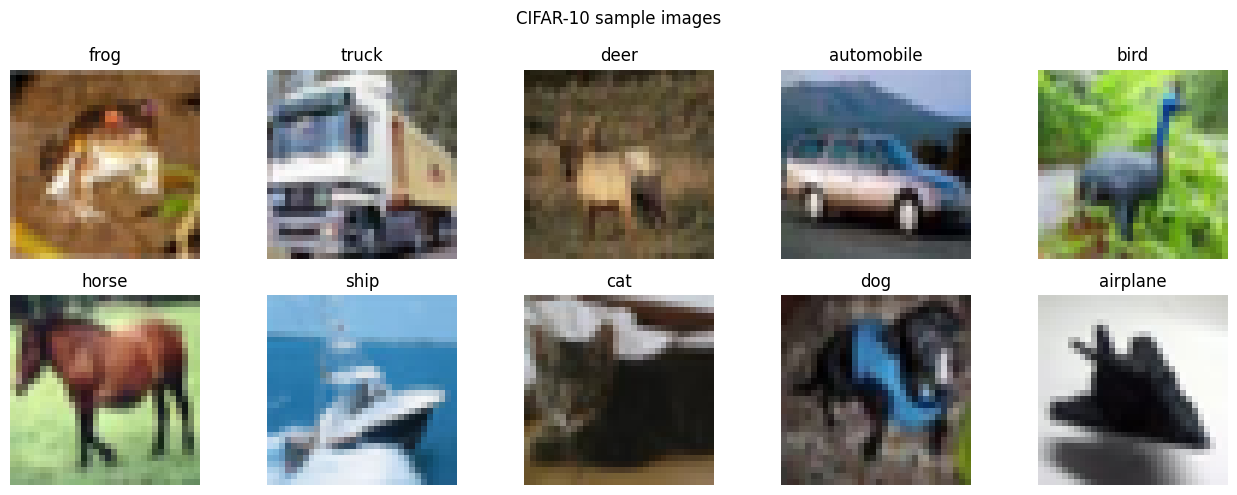

In [40]:
# Display one example from each class.
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
shown = set()
for image, label in raw_train_dataset:
    if label not in shown:
        ax = axes.flat[len(shown)]
        ax.imshow(image.permute(1, 2, 0).numpy())
        ax.set_title(class_names[label])
        ax.axis("off")
        shown.add(label)
    if len(shown) == 10:
        break
plt.suptitle("CIFAR-10 sample images")
plt.tight_layout()
plt.show()

,class,training_images
0,airplane,5000
1,automobile,5000
2,bird,5000
3,cat,5000
4,deer,5000
5,dog,5000
6,frog,5000
7,horse,5000
8,ship,5000
9,truck,5000


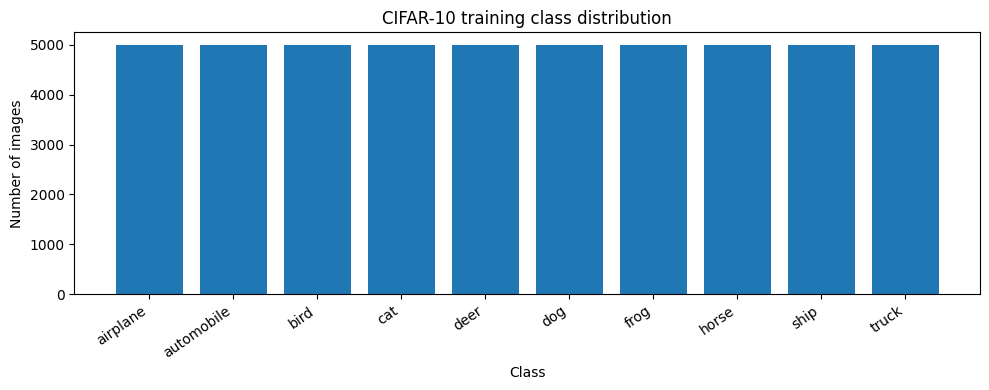

In [41]:
# Class distribution in the official training split.
train_label_counts = Counter(raw_train_dataset.targets)
class_distribution = pd.DataFrame({
    "class": class_names,
    "training_images": [train_label_counts[i] for i in range(NUM_CLASSES)]
})
display(class_distribution)

plt.figure(figsize=(10, 4))
plt.bar(class_distribution["class"], class_distribution["training_images"])
plt.title("CIFAR-10 training class distribution")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=160)
plt.show()

## 3. Preprocessing and train/validation/test split

The test set is kept separate until final evaluation. Ten percent of the original training data is held out for validation. The training subset uses random crop and horizontal flip augmentation; validation and test images are not augmented. All images are normalized using the commonly used CIFAR-10 channel statistics.

The paper reports the 10% cross-validation split for selecting ACLS lambda values. This notebook uses the published lambda values directly, and uses the held-out 10% as a validation set for monitoring training. State this implementation choice in your report.

In [42]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

# Separate dataset objects allow training augmentation only on training indices.
train_aug_dataset = torchvision.datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=False, transform=train_transform
)
train_eval_dataset = torchvision.datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=False, transform=eval_transform
)
test_dataset = torchvision.datasets.CIFAR10(
    root=str(DATA_DIR), train=False, download=False, transform=eval_transform
)

# Stratified 90/10 split, keeping the class proportions balanced.
targets = np.array(raw_train_dataset.targets)
rng = np.random.default_rng(SEED)
train_indices, val_indices = [], []
for class_id in range(NUM_CLASSES):
    class_indices = np.where(targets == class_id)[0]
    rng.shuffle(class_indices)
    n_val = int(round(len(class_indices) * VALIDATION_FRACTION))
    val_indices.extend(class_indices[:n_val].tolist())
    train_indices.extend(class_indices[n_val:].tolist())

rng.shuffle(train_indices)
rng.shuffle(val_indices)

train_subset = Subset(train_aug_dataset, train_indices)
val_subset = Subset(train_eval_dataset, val_indices)
test_subset = test_dataset

def make_loaders(seed=SEED):
    generator = torch.Generator()
    generator.manual_seed(seed)
    train_loader = DataLoader(
        train_subset, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
        generator=generator, persistent_workers=(NUM_WORKERS > 0)
    )
    val_loader = DataLoader(
        val_subset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=(NUM_WORKERS > 0)
    )
    test_loader = DataLoader(
        test_subset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=(NUM_WORKERS > 0)
    )
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders()

print("Training subset:", len(train_subset))
print("Validation subset:", len(val_subset))
print("Test set:", len(test_subset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training subset: 45000
Validation subset: 5000
Test set: 10000
Training batches: 352
Validation batches: 40
Test batches: 79


In [43]:
# Confirm one batch has the expected shapes and data types.
images, labels = next(iter(train_loader))
print("Image batch:", images.shape, images.dtype)
print("Label batch:", labels.shape, labels.dtype)
print("Normalized image range (batch):", images.min().item(), "to", images.max().item())

Image batch: torch.Size([128, 3, 32, 32]) torch.float32
Label batch: torch.Size([128]) torch.int64
Normalized image range (batch): -1.9894737005233765 to 2.12648868560791


## 4. ResNet-50 baseline architecture

Both experiments use the same ResNet-50 architecture and start from fresh random weights. Only the training loss changes. The final fully connected layer is changed to output 10 CIFAR-10 classes.

This keeps the architecture consistent with the ResNet-50 experiment in the paper and with the model you started in your earlier notebook. The standard torchvision ResNet-50 stem is retained; if the official configuration uses a different stem, record this as a reproduction deviation.

In [44]:

def build_model():
    model = resnet50(weights=None)

    # Adapt ResNet-50 for CIFAR-10 (32x32 images)
    model.conv1 = nn.Conv2d(
        3, 64,
        kernel_size=3,
        stride=1,
        padding=1,
        bias=False
    )

    model.maxpool = nn.Identity()

    # Change output layer to 10 classes
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

    return model.to(DEVICE)


# Create model for summary
model_summary_model = build_model()

# Count parameters
total_params = sum(
    p.numel() for p in model_summary_model.parameters()
)

trainable_params = sum(
    p.numel() for p in model_summary_model.parameters()
    if p.requires_grad
)

print(model_summary_model)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# Verify model output
with torch.no_grad():
    sample_x = torch.randn(4, 3, 32, 32, device=DEVICE)
    sample_logits = model_summary_model(sample_x)

print("Sample output shape:", tuple(sample_logits.shape))

del model_summary_model


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): Identity()
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (1): BatchNorm2d(256, eps=1e-05, momentu

## 5. Correct ACLS loss implementation

The paper defines the total objective as:

`Total loss = Cross-Entropy loss + ACLS regularization`

For the predicted class, ACLS applies a positive-class term based on the gap between the maximum and minimum logits. For every non-predicted class, it applies a conditional term based on the gap between the maximum logit and that class's logit. The margin controls when each term becomes active.

**Important correction to the earlier notebook:** the predicted-class term uses `max_logit - min_logit - margin`, not simply `max_logit - margin`. The paper's lambda values are applied inside the ACLS regularizer; do not multiply the entire regularizer by an additional `alpha=0.1`.

In [65]:
class ACLSLoss(nn.Module):
    """ACLS loss with detached reference logits."""

    def __init__(self, lambda1=0.1, lambda2=0.01, margin=6.0):
        super().__init__()

        self.lambda1 = float(lambda1)
        self.lambda2 = float(lambda2)
        self.margin = float(margin)

        self.ce = nn.CrossEntropyLoss()

    def forward(self, logits, targets):

        ce_loss = self.ce(logits, targets)

        max_logits, predicted_classes = logits.max(dim=1)
        min_logits = logits.min(dim=1).values

        predicted_logits = logits.gather(
            1, predicted_classes.unsqueeze(1)
        ).squeeze(1)

        max_reference = max_logits.detach()
        min_reference = min_logits.detach()

        # Positive term
        positive_gap = F.relu(
            predicted_logits - min_reference - self.margin
        )

        positive_term = (
            0.5 * self.lambda1 * positive_gap.pow(2)
        )

        # Non-predicted classes
        class_ids = torch.arange(
            logits.size(1), device=logits.device
        ).unsqueeze(0)

        non_predicted_mask = (
            class_ids != predicted_classes.unsqueeze(1)
        )

        # Negative term
        negative_gaps = F.relu(
            max_reference.unsqueeze(1)
            - logits
            - self.margin
        )

        negative_terms = (
            0.5
            * self.lambda2
            * negative_gaps.pow(2)
            * non_predicted_mask.float()
        )

        negative_term = negative_terms.sum(dim=1)

        acls_reg = (
            positive_term + negative_term
        ).mean()

        total_loss = ce_loss + acls_reg

        return (
            total_loss,
            ce_loss.detach(),
            acls_reg.detach()
        )

## 6. Training and checkpoint functions

The training function records training loss, validation loss and validation accuracy after each epoch. It saves a checkpoint after every epoch so training can be resumed if the Kaggle session stops.

The baseline and ACLS experiments are trained independently from fresh model initializations. The same seed and data split are used to make the comparison more controlled.

In [66]:
def evaluate_loss_and_accuracy(model, loader, criterion_type="ce"):

    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_count = 0

    ce_criterion = nn.CrossEntropyLoss()

    acls_criterion = ACLSLoss(
        ACLS_LAMBDA1,
        ACLS_LAMBDA2,
        ACLS_MARGIN
    )

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            logits = model(images)

            if criterion_type == "acls":
                loss, _, _ = acls_criterion(logits, labels)
            else:
                loss = ce_criterion(logits, labels)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size

            total_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()

            total_count += batch_size

    return (
        total_loss / total_count,
        total_correct / total_count
    )


def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion_type,
    scaler,
    epoch
):

    model.train()

    ce_criterion = nn.CrossEntropyLoss()

    acls_criterion = ACLSLoss(
        ACLS_LAMBDA1,
        ACLS_LAMBDA2,
        ACLS_MARGIN
    )

    running_loss = 0.0
    seen = 0

    for batch_idx, (images, labels) in enumerate(loader):

        if (
            MAX_TRAIN_BATCHES is not None
            and batch_idx >= MAX_TRAIN_BATCHES
        ):
            break

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)

        if criterion_type == "acls":

            loss, ce_component, acls_component = (
                acls_criterion(logits, labels)
            )

            if batch_idx < 10:
                print(f"\nBatch {batch_idx}")
                print("CE loss:", ce_component.item())
                print("ACLS regularizer:", acls_component.item())
                print("Total loss:", loss.item())
                print("Minimum logit:", logits.min().item())
                print("Maximum logit:", logits.max().item())

        else:
            loss = ce_criterion(logits, labels)

        # Check loss
        if not torch.isfinite(loss).item():
            raise RuntimeError(
                f"Non-finite loss at batch {batch_idx}"
            )

        # Backpropagation
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        # Check gradients
        grad_norm = torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRAD_CLIP_MAX_NORM
        )

        if not torch.isfinite(grad_norm).item():
            raise RuntimeError(
                f"Non-finite gradient norm at batch {batch_idx}"
            )

        if batch_idx >= 8:
            print(
                f"Batch {batch_idx} | "
                f"Gradient norm before clipping: "
                f"{grad_norm.item():.4f}"
            )

        # Optimizer update
        scaler.step(optimizer)
        scaler.update()

        # Check model parameters
        parameters_finite = all(
            torch.isfinite(param).all().item()
            for param in model.parameters()
        )

        if not parameters_finite:
            raise RuntimeError(
                f"Non-finite model parameters at batch {batch_idx}"
            )

        batch_size = labels.size(0)

        running_loss += loss.detach().item() * batch_size
        seen += batch_size

    return running_loss / max(seen, 1)


def train_experiment(experiment_name, criterion_type):

    seed_everything(SEED)

    train_loader_local, val_loader_local, _ = make_loaders(
        seed=SEED
    )

    model = build_model()

    optimizer = optim.SGD(
        model.parameters(),
        lr=LEARNING_RATE,
        momentum=MOMENTUM,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = optim.lr_scheduler.MultiStepLR(
        optimizer,
        milestones=LR_MILESTONES,
        gamma=LR_GAMMA
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP
    )

    artifact_prefix = f"{experiment_name}_{RUN_SUFFIX}"

    checkpoint_path = (
        MODELS_DIR / f"{artifact_prefix}_checkpoint.pth"
    )

    history_path = (
        OUTPUT_DIR / f"{artifact_prefix}_history.json"
    )

    final_model_path = (
        MODELS_DIR / f"{artifact_prefix}_final_model.pth"
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": [],
        "learning_rate": []
    }

    start_epoch = 0

    # Resume from an existing checkpoint
    if checkpoint_path.exists():

        checkpoint = torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=False
        )

        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        scheduler.load_state_dict(checkpoint["scheduler_state"])

        if "scaler_state" in checkpoint:
            scaler.load_state_dict(checkpoint["scaler_state"])

        history = checkpoint.get("history", history)

        start_epoch = checkpoint["epoch"] + 1

        print(
            f"Resuming {experiment_name} "
            f"from epoch {start_epoch + 1}"
        )

    start_time = time.time()

    for epoch in range(start_epoch, EPOCHS):

        epoch_start = time.time()

        train_loss = train_one_epoch(
            model,
            train_loader_local,
            optimizer,
            criterion_type,
            scaler,
            epoch
        )

        val_loss, val_accuracy = evaluate_loss_and_accuracy(
            model,
            val_loader_local,
            criterion_type
        )

        current_lr = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(float(train_loss))
        history["val_loss"].append(float(val_loss))
        history["val_accuracy"].append(float(val_accuracy))
        history["learning_rate"].append(float(current_lr))

        scheduler.step()

        # Save checkpoint after every epoch
        checkpoint = {
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "scaler_state": scaler.state_dict(),
            "history": history,
            "experiment_name": experiment_name,
            "criterion_type": criterion_type
        }

        torch.save(checkpoint, checkpoint_path)

        # Save training history
        with open(history_path, "w") as f:
            json.dump(history, f, indent=2)

        print(
            f"{experiment_name} | "
            f"Epoch {epoch + 1:03d}/{EPOCHS} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Val accuracy: {val_accuracy * 100:.2f}% | "
            f"LR: {current_lr:.6f} | "
            f"Time: {time.time() - epoch_start:.1f}s"
        )

    # Save final model
    torch.save(model.state_dict(), final_model_path)

    elapsed = time.time() - start_time

    print(f"\nFinished {experiment_name}")
    print(f"Time: {elapsed / 60:.1f} minutes")
    print("Saved model:", final_model_path)
    print("Saved history:", history_path)

    return model, history

## 7. Train the baseline model (ResNet-50 + Cross-Entropy)

Run this cell to train the baseline. In smoke-test mode it trains only a small number of batches for two epochs. For the actual assignment experiment, switch off smoke-test mode in Section 1, rerun the configuration cell and then run this training cell. Smoke-test and full-run checkpoints use different filenames, so the short test will not accidentally be resumed as the full experiment.

In [54]:
baseline_model, baseline_history = train_experiment(
    experiment_name="baseline_ce",
    criterion_type="ce"
)

Batch 8 | Gradient norm: 34.7800 | Gradients finite: True
Batch 9 | Gradient norm: 33.7570 | Gradients finite: True
Batch 10 | Gradient norm: 37.5911 | Gradients finite: True
Batch 11 | Gradient norm: 35.3409 | Gradients finite: True
Batch 12 | Gradient norm: 34.4209 | Gradients finite: True
Batch 13 | Gradient norm: 36.2120 | Gradients finite: True
Batch 14 | Gradient norm: 31.6507 | Gradients finite: True
Batch 15 | Gradient norm: 33.5108 | Gradients finite: True
Batch 16 | Gradient norm: 31.4825 | Gradients finite: True
Batch 17 | Gradient norm: 34.6735 | Gradients finite: True
Batch 18 | Gradient norm: 33.9480 | Gradients finite: True
Batch 19 | Gradient norm: 34.5896 | Gradients finite: True
Batch 20 | Gradient norm: 31.9393 | Gradients finite: True
Batch 21 | Gradient norm: 33.3145 | Gradients finite: True
Batch 22 | Gradient norm: 31.4036 | Gradients finite: True
Batch 23 | Gradient norm: 32.1361 | Gradients finite: True
Batch 24 | Gradient norm: 29.6460 | Gradients finite: True

## 8. Train the ACLS model (same ResNet-50 + ACLS)

This creates a new ResNet-50 with fresh weights. It does not continue training the baseline model.

In [67]:
acls_model, acls_history = train_experiment(
    experiment_name="acls",
    criterion_type="acls"
)


Batch 0
CE loss: 2.789409637451172
ACLS regularizer: 0.003224003128707409
Total loss: 2.792633533477783
Minimum logit: -4.778440952301025
Maximum logit: 3.962287664413452

Batch 1
CE loss: 2.5222463607788086
ACLS regularizer: 0.031251825392246246
Total loss: 2.5534982681274414
Minimum logit: -7.406649112701416
Maximum logit: 6.443605422973633

Batch 2
CE loss: 2.604172706604004
ACLS regularizer: 0.009479612112045288
Total loss: 2.613652229309082
Minimum logit: -5.534430027008057
Maximum logit: 4.62451696395874

Batch 3
CE loss: 2.61366605758667
ACLS regularizer: 0.021025827154517174
Total loss: 2.6346919536590576
Minimum logit: -7.126981258392334
Maximum logit: 5.679698944091797

Batch 4
CE loss: 2.514962911605835
ACLS regularizer: 0.003925129771232605
Total loss: 2.518887996673584
Minimum logit: -4.606677055358887
Maximum logit: 3.5435516834259033

Batch 5
CE loss: 2.5639584064483643
ACLS regularizer: 0.019810110330581665
Total loss: 2.583768606185913
Minimum logit: -5.77064371109008

In [68]:
baseline_model.eval()

images, labels = next(iter(val_loader))
images = images.to(DEVICE)

with torch.no_grad():
    logits = baseline_model(images)
    probabilities = torch.softmax(logits, dim=1)

print("Logits finite:", torch.isfinite(logits).all().item())
print("Logit minimum:", logits.min().item())
print("Logit maximum:", logits.max().item())

print("Probability minimum:", probabilities.min().item())
print("Probability maximum:", probabilities.max().item())

print("Average maximum confidence:",
      probabilities.max(dim=1).values.mean().item())

print("Predicted classes:",
      torch.unique(logits.argmax(dim=1)).tolist())

Logits finite: True
Logit minimum: -6.286879062652588
Logit maximum: 9.098262786865234
Probability minimum: 1.6684864476701478e-06
Probability maximum: 0.9309423565864563
Average maximum confidence: 0.48184990882873535
Predicted classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


## 9. Training curves

These graphs are saved to the output folder and can be included in the technical report.

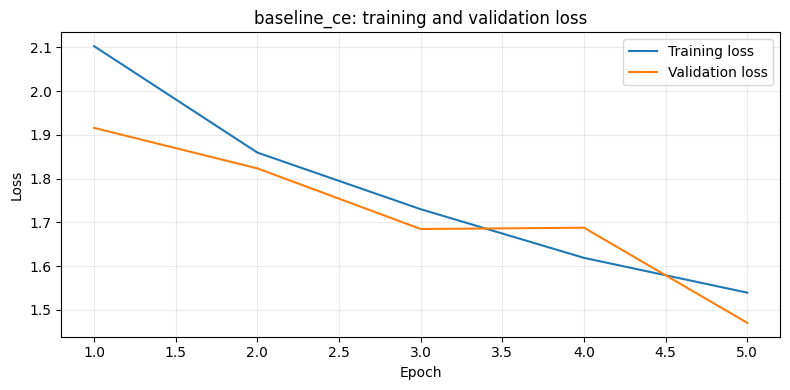

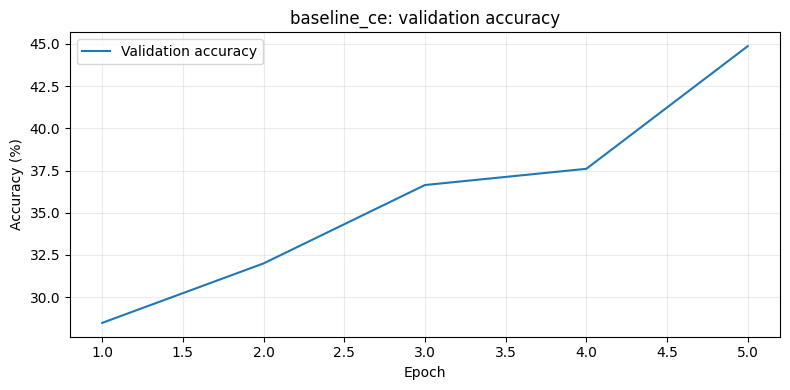

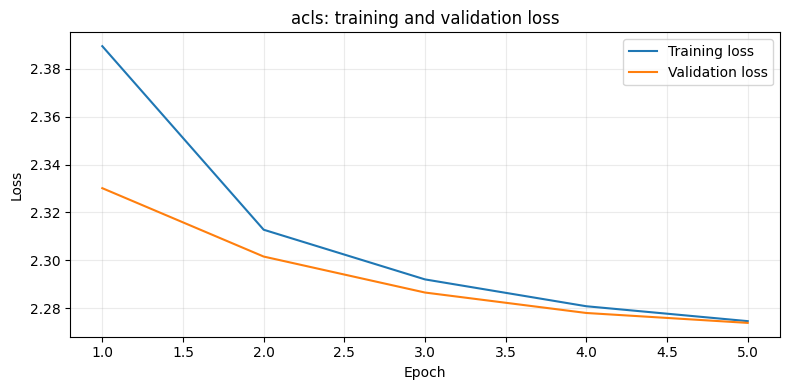

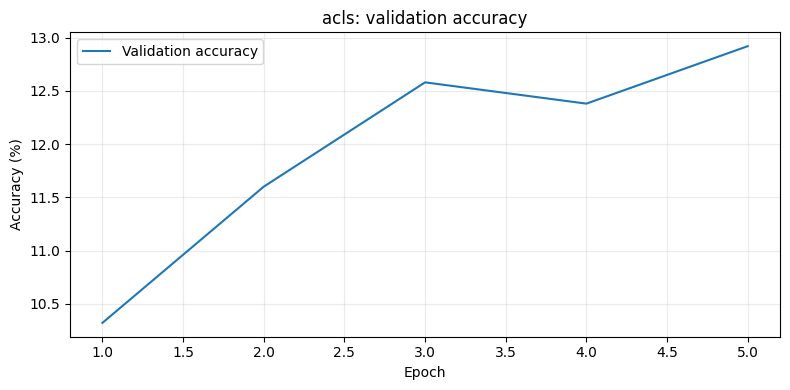

In [69]:
def plot_training_history(history, name):
    epochs = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(8, 4))
    plt.plot(epochs, history["train_loss"], label="Training loss")
    plt.plot(epochs, history["val_loss"], label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{name}: training and validation loss")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    path = OUTPUT_DIR / f"{name}_loss_curves.png"
    plt.savefig(path, dpi=160)
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.plot(epochs, np.array(history["val_accuracy"]) * 100, label="Validation accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title(f"{name}: validation accuracy")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    path = OUTPUT_DIR / f"{name}_validation_accuracy.png"
    plt.savefig(path, dpi=160)
    plt.show()

plot_training_history(baseline_history, "baseline_ce")
plot_training_history(acls_history, "acls")

## 10. Calibration metrics: Accuracy, ECE and AECE

- **Accuracy:** percentage of correctly classified images.
- **ECE:** average confidence-accuracy gap using equal-width confidence bins.
- **AECE:** calibration error using adaptive/equal-count bins.

The paper reports ECE and AECE with 15 bins. This notebook also uses 15 bins. Metric implementations can differ slightly between libraries, so describe the binning convention in the report.

In [75]:
@torch.no_grad()
def collect_predictions(model, loader):
    model.eval()
    all_logits, all_labels = [], []
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(images)
        all_logits.append(logits.float().cpu())
        all_labels.append(labels.cpu())
    return torch.cat(all_logits), torch.cat(all_labels)


def calibration_metrics(logits, labels, n_bins=15):
    probs = torch.softmax(logits, dim=1)
    confidences, predictions = probs.max(dim=1)
    accuracies = predictions.eq(labels).float()

    accuracy = accuracies.mean().item()

    # Equal-width bins: standard ECE.
    ece = torch.tensor(0.0)
    bin_boundaries = torch.linspace(0, 1, n_bins + 1)
    ece_bins = []
    for i in range(n_bins):
        lower, upper = bin_boundaries[i], bin_boundaries[i + 1]
        if i == 0:
            mask = (confidences >= lower) & (confidences <= upper)
        else:
            mask = (confidences > lower) & (confidences <= upper)
        if mask.any():
            bin_conf = confidences[mask].mean()
            bin_acc = accuracies[mask].mean()
            bin_gap = torch.abs(bin_acc - bin_conf)
            ece += mask.float().mean() * bin_gap
            ece_bins.append((float(bin_conf), float(bin_acc), int(mask.sum())))
        else:
            ece_bins.append((np.nan, np.nan, 0))

    # Adaptive ECE: sort by confidence and divide into approximately equal-count bins.
    sorted_indices = torch.argsort(confidences)
    chunks = torch.tensor_split(sorted_indices, n_bins)
    aece = torch.tensor(0.0)
    aece_bins = []
    for chunk in chunks:
        if len(chunk) == 0:
            continue
        bin_conf = confidences[chunk].mean()
        bin_acc = accuracies[chunk].mean()
        aece += (len(chunk) / len(labels)) * torch.abs(bin_acc - bin_conf)
        aece_bins.append((float(bin_conf), float(bin_acc), int(len(chunk))))

    return {
        "accuracy": accuracy * 100,
        "ece": ece.item() * 100,
        "aece": aece.item() * 100,
        "ece_bins": ece_bins,
        "aece_bins": aece_bins,
        "confidences": confidences,
        "correctness": accuracies
    }


def reliability_diagram(metrics, title, filename):
    bins = metrics["ece_bins"]
    conf = [x[0] for x in bins if x[2] > 0]
    acc = [x[1] for x in bins if x[2] > 0]
    plt.figure(figsize=(5.5, 5))
    plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")
    plt.plot(conf, acc, marker="o", label="Model")
    plt.xlabel("Mean confidence")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=160)
    plt.show()

## 11. Final evaluation on the untouched test set

This is the final evaluation. Do not use test results to tune learning rates, epochs or ACLS hyperparameters. If the models were only smoke-tested, these metrics are pipeline checks and must not be presented as final reproduction results.

Output directories ready!
Both models loaded successfully!
Predictions collected successfully!
Baseline logits shape: torch.Size([10000, 10])
ACLS logits shape: torch.Size([10000, 10])
Test labels shape: torch.Size([10000])
Metrics calculated successfully!

FINAL TEST RESULTS


,Model,Accuracy (%),ECE (%),AECE (%)
0,Baseline CE,45.84,2.388,2.388
1,ACLS,13.25,1.138,1.017


Results saved to: /kaggle/working/ACLS_Final_Results/reproduced_test_results.csv


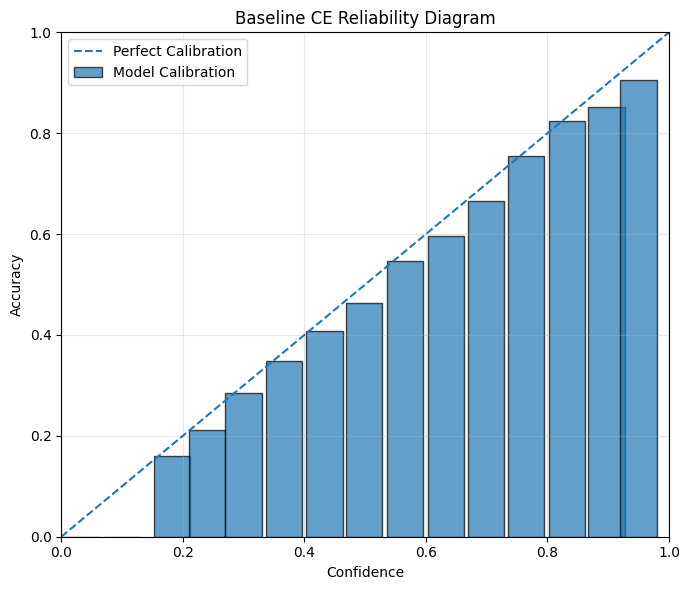

Saved: /kaggle/working/ACLS_Final_Results/calibration/baseline_reliability.png


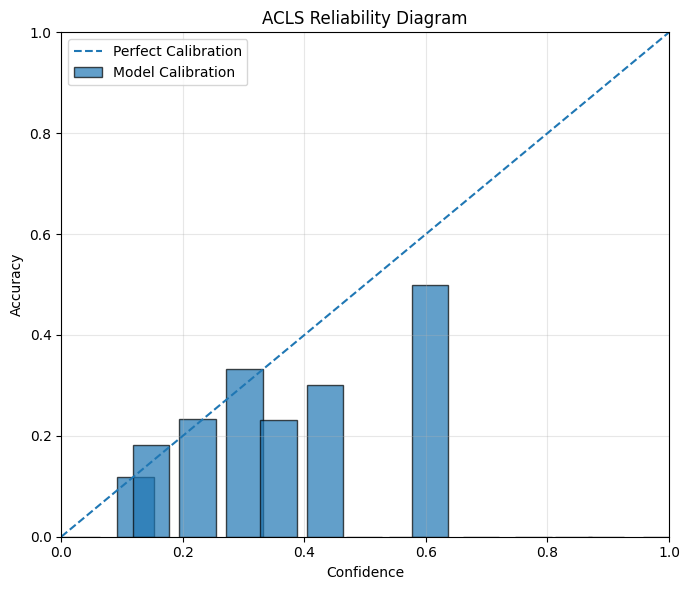

Saved: /kaggle/working/ACLS_Final_Results/calibration/acls_reliability.png

ORIGINAL VS REPRODUCED COMPARISON


,Model,Original Accuracy (%),Original ECE (%),Original AECE (%),Reproduced Accuracy (%),Reproduced ECE (%),Reproduced AECE (%)
0,Baseline CE,93.2,5.85,5.84,45.84,2.388,2.388
1,ACLS,95.4,1.12,2.87,13.25,1.138,1.017


Comparison saved to: /kaggle/working/ACLS_Final_Results/original_vs_reproduced_comparison.csv

GENERATED FILES:
/kaggle/working/ACLS_Final_Results/acls_acls_full5_stable_run3_history.json
/kaggle/working/ACLS_Final_Results/acls_loss_curves.png
/kaggle/working/ACLS_Final_Results/baseline_ce_loss_curves.png
/kaggle/working/ACLS_Final_Results/baseline_ce_validation_accuracy.png
/kaggle/working/ACLS_Final_Results/reproduced_test_results.csv
/kaggle/working/ACLS_Final_Results/acls_validation_accuracy.png
/kaggle/working/ACLS_Final_Results/original_vs_reproduced_comparison.csv
/kaggle/working/ACLS_Final_Results/models/acls_acls_full5_stable_run3_checkpoint.pth
/kaggle/working/ACLS_Final_Results/models/acls_acls_full5_stable_run3_final_model.pth
/kaggle/working/ACLS_Final_Results/calibration/acls_reliability.png
/kaggle/working/ACLS_Final_Results/calibration/baseline_reliability.png

EVALUATION COMPLETED SUCCESSFULLY!


In [79]:
# ============================================================
# STEP 1: IMPORT LIBRARIES AND CREATE OUTPUT DIRECTORIES
# ============================================================

import os
import csv
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from pathlib import Path

# Output directories
OUTPUT_DIR = Path("/kaggle/working/ACLS_Final_Results")
MODELS_DIR = OUTPUT_DIR / "models"
CALIBRATION_DIR = OUTPUT_DIR / "calibration"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
CALIBRATION_DIR.mkdir(parents=True, exist_ok=True)

print("Output directories ready!")


# ============================================================
# STEP 2: LOAD BOTH TRAINED MODELS
# ============================================================

# Baseline model path
baseline_path = Path(
    "/kaggle/working/acls_reproduction/"
    "baseline_ce_baseline_ce_full5_run2_final_model.pth"
)

# ACLS model path
acls_path = (
    MODELS_DIR /
    "acls_acls_full5_stable_run3_final_model.pth"
)

# Check whether both files exist
if not baseline_path.exists():
    raise FileNotFoundError(f"Baseline model not found: {baseline_path}")

if not acls_path.exists():
    raise FileNotFoundError(f"ACLS model not found: {acls_path}")


# Function to load saved model weights
def load_saved_model(model_path):

    model = build_model()

    checkpoint = torch.load(
        model_path,
        map_location=DEVICE,
        weights_only=True
    )

    # Support either a raw state_dict or a checkpoint dictionary
    if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    else:
        state_dict = checkpoint

    model.load_state_dict(state_dict)
    model.eval()

    return model


baseline_model = load_saved_model(baseline_path)
acls_model = load_saved_model(acls_path)

print("Both models loaded successfully!")


# ============================================================
# STEP 3: COLLECT PREDICTIONS
# ============================================================

@torch.no_grad()
def collect_predictions(model, loader):

    model.eval()

    all_logits = []
    all_labels = []

    for images, labels in loader:

        images = images.to(DEVICE, non_blocking=True)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP
        ):
            logits = model(images)

        all_logits.append(logits.float().cpu())
        all_labels.append(labels.cpu())

    all_logits = torch.cat(all_logits)
    all_labels = torch.cat(all_labels)

    return all_logits, all_labels


# Collect Baseline predictions
baseline_logits, baseline_labels = collect_predictions(
    baseline_model,
    test_loader
)

# Collect ACLS predictions
acls_logits, acls_labels = collect_predictions(
    acls_model,
    test_loader
)

print("Predictions collected successfully!")

print("Baseline logits shape:", baseline_logits.shape)
print("ACLS logits shape:", acls_logits.shape)
print("Test labels shape:", baseline_labels.shape)


# ============================================================
# STEP 4: CALCULATE ACCURACY, ECE AND AECE
# ============================================================

def calibration_metrics(logits, labels, num_bins=15):

    probabilities = F.softmax(logits, dim=1)

    confidences, predictions = probabilities.max(dim=1)

    correct = predictions.eq(labels).float()

    # Accuracy in percentage
    accuracy = correct.mean().item() * 100

    # Convert tensors to NumPy
    confidences = confidences.numpy()
    correct = correct.numpy()

    # --------------------------------------------------------
    # ECE: Equal-width bins
    # --------------------------------------------------------

    bin_boundaries = np.linspace(0, 1, num_bins + 1)

    ece = 0.0

    for i in range(num_bins):

        lower = bin_boundaries[i]
        upper = bin_boundaries[i + 1]

        if i == num_bins - 1:
            mask = (confidences >= lower) & (confidences <= upper)
        else:
            mask = (confidences >= lower) & (confidences < upper)

        if np.any(mask):

            bin_accuracy = correct[mask].mean()
            bin_confidence = confidences[mask].mean()
            bin_fraction = mask.mean()

            ece += bin_fraction * abs(
                bin_accuracy - bin_confidence
            )

    # --------------------------------------------------------
    # AECE: Equal-count bins
    # --------------------------------------------------------

    sorted_indices = np.argsort(confidences)
    confidence_sorted = confidences[sorted_indices]
    correct_sorted = correct[sorted_indices]

    confidence_bins = np.array_split(
        np.arange(len(confidences)),
        num_bins
    )

    aece = 0.0

    for bin_indices in confidence_bins:

        if len(bin_indices) == 0:
            continue

        bin_accuracy = correct_sorted[bin_indices].mean()
        bin_confidence = confidence_sorted[bin_indices].mean()

        bin_fraction = len(bin_indices) / len(confidences)

        aece += bin_fraction * abs(
            bin_accuracy - bin_confidence
        )

    return {
        "Accuracy": accuracy,
        "ECE": ece * 100,
        "AECE": aece * 100,
        "confidences": confidences,
        "correct": correct
    }


# Calculate metrics for both models
baseline_metrics = calibration_metrics(
    baseline_logits,
    baseline_labels
)

acls_metrics = calibration_metrics(
    acls_logits,
    acls_labels
)

print("Metrics calculated successfully!")


# ============================================================
# STEP 5: DISPLAY RESULTS
# ============================================================

results_df = pd.DataFrame([
    {
        "Model": "Baseline CE",
        "Accuracy (%)": baseline_metrics["Accuracy"],
        "ECE (%)": baseline_metrics["ECE"],
        "AECE (%)": baseline_metrics["AECE"]
    },
    {
        "Model": "ACLS",
        "Accuracy (%)": acls_metrics["Accuracy"],
        "ECE (%)": acls_metrics["ECE"],
        "AECE (%)": acls_metrics["AECE"]
    }
])

print("\nFINAL TEST RESULTS")
display(results_df.round(3))


# ============================================================
# STEP 6: SAVE RESULTS AS CSV
# ============================================================

results_csv_path = OUTPUT_DIR / "reproduced_test_results.csv"

results_df.to_csv(
    results_csv_path,
    index=False
)

print("Results saved to:", results_csv_path)


# ============================================================
# STEP 7: GENERATE RELIABILITY DIAGRAMS
# ============================================================

def reliability_diagram(metrics, title, filename, num_bins=15):

    confidences = metrics["confidences"]
    correct = metrics["correct"]

    bin_boundaries = np.linspace(0, 1, num_bins + 1)

    bin_accuracies = []
    bin_confidences = []
    bin_sizes = []

    for i in range(num_bins):

        lower = bin_boundaries[i]
        upper = bin_boundaries[i + 1]

        if i == num_bins - 1:
            mask = (confidences >= lower) & (confidences <= upper)
        else:
            mask = (confidences >= lower) & (confidences < upper)

        if np.any(mask):

            bin_accuracies.append(correct[mask].mean())
            bin_confidences.append(confidences[mask].mean())
            bin_sizes.append(mask.sum())

        else:

            bin_accuracies.append(0)
            bin_confidences.append((lower + upper) / 2)
            bin_sizes.append(0)

    # Plot reliability diagram
    plt.figure(figsize=(7, 6))

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect Calibration"
    )

    plt.bar(
        bin_confidences,
        bin_accuracies,
        width=0.06,
        alpha=0.7,
        edgecolor="black",
        label="Model Calibration"
    )

    plt.xlabel("Confidence")
    plt.ylabel("Accuracy")
    plt.title(title)

    plt.xlim(0, 1)
    plt.ylim(0, 1)

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()

    save_path = CALIBRATION_DIR / filename

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print("Saved:", save_path)


# Baseline reliability diagram
reliability_diagram(
    baseline_metrics,
    "Baseline CE Reliability Diagram",
    "baseline_reliability.png"
)

# ACLS reliability diagram
reliability_diagram(
    acls_metrics,
    "ACLS Reliability Diagram",
    "acls_reliability.png"
)


# ============================================================
# STEP 8: SAVE ORIGINAL VS REPRODUCED COMPARISON TABLE
# ============================================================

# Original paper's CIFAR-10 validation results
# These are validation results, not test results.

comparison_df = pd.DataFrame([
    {
        "Model": "Baseline CE",
        "Original Accuracy (%)": 93.20,
        "Original ECE (%)": 5.85,
        "Original AECE (%)": 5.84,
        "Reproduced Accuracy (%)": baseline_metrics["Accuracy"],
        "Reproduced ECE (%)": baseline_metrics["ECE"],
        "Reproduced AECE (%)": baseline_metrics["AECE"]
    },
    {
        "Model": "ACLS",
        "Original Accuracy (%)": 95.40,
        "Original ECE (%)": 1.12,
        "Original AECE (%)": 2.87,
        "Reproduced Accuracy (%)": acls_metrics["Accuracy"],
        "Reproduced ECE (%)": acls_metrics["ECE"],
        "Reproduced AECE (%)": acls_metrics["AECE"]
    }
])

comparison_csv_path = (
    OUTPUT_DIR / "original_vs_reproduced_comparison.csv"
)

comparison_df.to_csv(
    comparison_csv_path,
    index=False
)

print("\nORIGINAL VS REPRODUCED COMPARISON")
display(comparison_df.round(3))

print("Comparison saved to:", comparison_csv_path)


# ============================================================
# STEP 9: CHECK ALL GENERATED FILES
# ============================================================

print("\nGENERATED FILES:")

for root, dirs, files in os.walk(OUTPUT_DIR):

    for file in files:

        print(os.path.join(root, file))


print("\nEVALUATION COMPLETED SUCCESSFULLY!")

## 12. Compare with the original paper's CIFAR-10 results

The paper's Table 3 reports the following results for **CIFAR-10 + ResNet-50**:

| Method | Accuracy (%) | ECE (%) | AECE (%) |
|---|---:|---:|---:|
| Cross-Entropy (CE) | 93.20 | 5.85 | 5.84 |
| ACLS | 95.40 | 1.12 | 2.87 |

These are the CIFAR-10 results to use as the closest paper comparison—not the 1.05% ECE figure from your Assignment 1, which refers to Tiny-ImageNet with ResNet-50.

The original paper reports results on its validation split. This notebook evaluates on a held-out test split, so the protocols are not identical. Compare them transparently and explain the split difference rather than claiming exact reproduction.

In [82]:
paper_results = pd.DataFrame([
    {"Model": "Baseline (CE)", "Original paper Accuracy (%)": 93.20,
     "Original paper ECE (%)": 5.85, "Original paper AECE (%)": 5.84},
    {"Model": "ACLS", "Original paper Accuracy (%)": 95.40,
     "Original paper ECE (%)": 1.12, "Original paper AECE (%)": 2.87}
])

our_results = results_df.copy()
comparison = paper_results.merge(our_results, on="Model", how="left")
for metric, paper_col, our_col in [
    ("Accuracy", "Original paper Accuracy (%)", "Accuracy (%)"),
    ("ECE", "Original paper ECE (%)", "ECE (%)"),
    ("AECE", "Original paper AECE (%)", "AECE (%)")
]:
    comparison[f"{metric} difference (ours - paper)"] = comparison[our_col] - comparison[paper_col]

display(comparison.round(3))
comparison.to_csv(OUTPUT_DIR / "original_vs_reproduced_comparison.csv", index=False)

,Model,Original paper Accuracy (%),Original paper ECE (%),Original paper AECE (%),Accuracy (%),ECE (%),AECE (%),Accuracy difference (ours - paper),ECE difference (ours - paper),AECE difference (ours - paper)
0,Baseline (CE),93.2,5.85,5.84,NaN,NaN,NaN,NaN,NaN,NaN
1,ACLS,95.4,1.12,2.87,13.25,1.138,1.017,-82.15,0.018,-1.853


## 13. Save experiment configuration and environment

Keep this file with the notebook and include the software/hardware details in the report.

In [18]:
experiment_config = {
    "paper": "ACLS: Adaptive and Conditional Label Smoothing for Network Calibration (ICCV 2023)",
    "dataset": "CIFAR-10",
    "architecture": "torchvision ResNet-50, final layer changed to 10 classes",
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "python": sys.version,
    "pytorch": torch.__version__,
    "torchvision": torchvision.__version__,
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "epochs_configured": EPOCHS,
    "smoke_test": SMOKE_TEST,
    "max_train_batches_per_epoch": MAX_TRAIN_BATCHES,
    "optimizer": "SGD",
    "learning_rate": LEARNING_RATE,
    "momentum": MOMENTUM,
    "weight_decay": WEIGHT_DECAY,
    "lr_milestones": LR_MILESTONES,
    "lr_gamma": LR_GAMMA,
    "validation_fraction": VALIDATION_FRACTION,
    "augmentation": ["RandomCrop(32, padding=4)", "RandomHorizontalFlip"],
    "normalization_mean": CIFAR_MEAN,
    "normalization_std": CIFAR_STD,
    "acls_margin": ACLS_MARGIN,
    "acls_lambda1": ACLS_LAMBDA1,
    "acls_lambda2": ACLS_LAMBDA2,
    "calibration_bins": 15
}

with open(OUTPUT_DIR / "experiment_config.json", "w") as f:
    json.dump(experiment_config, f, indent=2)

print(json.dumps(experiment_config, indent=2))

{
  "paper": "ACLS: Adaptive and Conditional Label Smoothing for Network Calibration (ICCV 2023)",
  "dataset": "CIFAR-10",
  "architecture": "torchvision ResNet-50, final layer changed to 10 classes",
  "device": "cuda",
  "gpu": "Tesla T4",
  "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "pytorch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "seed": 42,
  "batch_size": 128,
  "epochs_configured": 5,
  "smoke_test": true,
  "max_train_batches_per_epoch": null,
  "optimizer": "SGD",
  "learning_rate": 0.001,
  "momentum": 0.9,
  "weight_decay": 0.0005,
  "lr_milestones": [],
  "lr_gamma": 0.1,
  "validation_fraction": 0.1,
  "augmentation": [
    "RandomCrop(32, padding=4)",
    "RandomHorizontalFlip"
  ],
  "normalization_mean": [
    0.4914,
    0.4822,
    0.4465
  ],
  "normalization_std": [
    0.247,
    0.2435,
    0.2616
  ],
  "acls_margin": 6.0,
  "acls_lambda1": 0.1,
  "acls_lambda2": 0.01,
  "calibration_bins": 15
}


## 14. Export a compact results summary

This creates a text summary you can use while writing the report. It does not write conclusions automatically: explain the results you actually obtained.

In [81]:
summary_lines = [
    "ACLS CIFAR-10 Reproduction — Results Summary",
    "=" * 48,
    f"Experiment mode: {'SMOKE TEST (not final results)' if SMOKE_TEST else 'FULL RUN'}",
    f"Device: {DEVICE}",
    "",
    "Reproduced test metrics:",
    results_df.to_string(index=False),
    "",
    "Original paper CIFAR-10 / ResNet-50 reference:",
    paper_results.to_string(index=False),
    "",
    "Important protocol note:",
    "The paper reports validation-split results; this notebook reports the held-out test split.",
    "Do not claim exact reproduction if the data split, augmentation, stem, software or hardware differ."
]
summary_text = "\n".join(summary_lines)
print(summary_text)
with open(OUTPUT_DIR / "results_summary.txt", "w") as f:
    f.write(summary_text)

ACLS CIFAR-10 Reproduction — Results Summary
Experiment mode: FULL RUN
Device: cuda

Reproduced test metrics:
      Model  Accuracy (%)  ECE (%)  AECE (%)
Baseline CE     45.840001 2.387858  2.387860
       ACLS     13.249999 1.138310  1.017359

Original paper CIFAR-10 / ResNet-50 reference:
        Model  Original paper Accuracy (%)  Original paper ECE (%)  Original paper AECE (%)
Baseline (CE)                         93.2                    5.85                     5.84
         ACLS                         95.4                    1.12                     2.87

Important protocol note:
The paper reports validation-split results; this notebook reports the held-out test split.
Do not claim exact reproduction if the data split, augmentation, stem, software or hardware differ.


## 15. Required files for the Assignment 02 submission

After the full run, the output directory should contain:

- `baseline_ce_final_model.pth`
- `acls_final_model.pth`
- `baseline_ce_history.json`
- `acls_history.json`
- `class_distribution.png`
- `baseline_ce_loss_curves.png`
- `acls_loss_curves.png`
- `baseline_ce_validation_accuracy.png`
- `acls_validation_accuracy.png`
- `baseline_reliability.png`
- `acls_reliability.png`
- `reproduced_test_results.csv`
- `original_vs_reproduced_comparison.csv`
- `experiment_config.json`
- `results_summary.txt`

You still need to write the human parts of the assignment: the 5–7 page technical report, the reproducibility discussion, and the README. Do not invent results. Use the outputs generated by your completed full run.

### References

- Park, H., Noh, J., Oh, Y., Baek, D., & Ham, B. (2023). *ACLS: Adaptive and Conditional Label Smoothing for Network Calibration*. ICCV. https://openaccess.thecvf.com/content/ICCV2023/html/Park_ACLS_Adaptive_and_Conditional_Label_Smoothing_for_Network_Calibration_ICCV_2023_paper.html
- Official PyTorch implementation: https://github.com/cvlab-yonsei/ACLS

In [22]:
# Check whether the trained models contain invalid values

for name, model in [
    ("Baseline CE", baseline_model),
    ("ACLS", acls_model)
]:
    model.eval()

    params_finite = all(
        torch.isfinite(p).all().item()
        for p in model.parameters()
    )

    images, labels = next(iter(val_loader))
    images = images.to(DEVICE)

    with torch.no_grad():
        logits = model(images)

    print(f"\n{name}")
    print("All model parameters finite:", params_finite)
    print("All logits finite:", torch.isfinite(logits).all().item())
    print("Logit minimum:", logits.min().item())
    print("Logit maximum:", logits.max().item())
    print("Predicted classes:", torch.unique(logits.argmax(dim=1)).tolist())


Baseline CE
All model parameters finite: True
All logits finite: True
Logit minimum: -52381.9140625
Logit maximum: 28534.521484375
Predicted classes: [2, 6, 7, 8]

ACLS
All model parameters finite: True
All logits finite: False
Logit minimum: nan
Logit maximum: nan
Predicted classes: [0]


In [23]:

# Disable mixed precision for numerical stability
USE_AMP = False

# Remove old smoke-test checkpoints and results
old_files = [
    "baseline_ce_smoke_checkpoint.pth",
    "baseline_ce_smoke_history.json",
    "baseline_ce_smoke_final_model.pth",
    "acls_smoke_checkpoint.pth",
    "acls_smoke_history.json",
    "acls_smoke_final_model.pth"
]

for filename in old_files:
    path = OUTPUT_DIR / filename
    if path.exists():
        path.unlink()
        print("Deleted:", filename)

print("\nMixed precision enabled:", USE_AMP)
print("Ready for a fresh smoke test.")


Deleted: baseline_ce_smoke_checkpoint.pth
Deleted: baseline_ce_smoke_history.json
Deleted: baseline_ce_smoke_final_model.pth
Deleted: acls_smoke_checkpoint.pth
Deleted: acls_smoke_history.json
Deleted: acls_smoke_final_model.pth

Mixed precision enabled: False
Ready for a fresh smoke test.


In [28]:
# Fix DataLoader worker issue

NUM_WORKERS = 0
USE_AMP = False

# Recreate all DataLoaders
train_loader, val_loader, test_loader = make_loaders()

print("Workers:", NUM_WORKERS)
print("Mixed precision:", USE_AMP)
print("Validation batches:", len(val_loader))

# Test validation DataLoader
images, labels = next(iter(val_loader))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("DataLoader working successfully!")

Workers: 0
Mixed precision: False
Validation batches: 40
Image shape: torch.Size([128, 3, 32, 32])
Label shape: torch.Size([128])
DataLoader working successfully!


In [30]:
print("Learning rate:", LEARNING_RATE)
print("Momentum:", MOMENTUM)
print("Weight decay:", WEIGHT_DECAY)
print("Batch size:", BATCH_SIZE)
print("Mixed precision:", USE_AMP)
print("Workers:", NUM_WORKERS)

print("\nBaseline history:")
print(baseline_history)

Learning rate: 0.1
Momentum: 0.9
Weight decay: 0.0005
Batch size: 128
Mixed precision: False
Workers: 0

Baseline history:
{'train_loss': [21.530744779109956, 13.804173946380615], 'val_loss': [93110811.392, 583.4731526855469], 'val_accuracy': [0.1, 0.1094], 'learning_rate': [0.1, 0.1]}


In [32]:
print("ResNet-50 first convolution:")
print(baseline_model.conv1)

print("\nResNet-50 max pooling:")
print(baseline_model.maxpool)

print("\nFinal classification layer:")
print(baseline_model.fc)

print("\nFinal layer weight maximum:")
print(baseline_model.fc.weight.abs().max().item())

print("\nFinal layer bias maximum:")
print(baseline_model.fc.bias.abs().max().item())

ResNet-50 first convolution:
Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)

ResNet-50 max pooling:
MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)

Final classification layer:
Linear(in_features=2048, out_features=10, bias=True)

Final layer weight maximum:
0.7905471920967102

Final layer bias maximum:
0.9592854380607605


In [78]:

acls_model.eval()

_, val_loader_diag, _ = make_loaders(seed=SEED)

diagnostic_criterion = ACLSLoss(
    ACLS_LAMBDA1,
    ACLS_LAMBDA2,
    ACLS_MARGIN
)

with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(val_loader_diag):

        if batch_idx >= 3:
            break

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        logits = acls_model(images)

        total_loss, ce_loss, acls_reg = diagnostic_criterion(
            logits, labels
        )

        print(f"\nValidation batch {batch_idx}")
        print("Logits finite:", torch.isfinite(logits).all().item())
        print("Minimum logit:", logits.min().item())
        print("Maximum logit:", logits.max().item())
        print("CE loss:", ce_loss.item())
        print("ACLS regularizer:", acls_reg.item())
        print("Total loss:", total_loss.item())



Validation batch 0
Logits finite: True
Minimum logit: -69702.484375
Maximum logit: 825.1710815429688
CE loss: 2656.519287109375
ACLS regularizer: 30904136.0
Total loss: 30906792.0

Validation batch 1
Logits finite: True
Minimum logit: -62578.3125
Maximum logit: 741.378173828125
CE loss: 2226.930419921875
ACLS regularizer: 33810576.0
Total loss: 33812804.0

Validation batch 2
Logits finite: True
Minimum logit: -84806.0625
Maximum logit: 1001.5733642578125
CE loss: 2330.125244140625
ACLS regularizer: 51260392.0
Total loss: 51262724.0


In [79]:

baseline_model.eval()

with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(val_loader_diag):

        if batch_idx >= 3:
            break

        images = images.to(DEVICE)

        logits = baseline_model(images)

        print(f"\nBaseline validation batch {batch_idx}")
        print("Logits finite:", torch.isfinite(logits).all().item())
        print("Minimum logit:", logits.min().item())
        print("Maximum logit:", logits.max().item())
        print("Average maximum confidence:",
              torch.softmax(logits, dim=1).max(dim=1).values.mean().item())



Baseline validation batch 0
Logits finite: True
Minimum logit: -57.79578399658203
Maximum logit: 45.97032165527344
Average maximum confidence: 0.2214859277009964

Baseline validation batch 1
Logits finite: True
Minimum logit: -321.6407775878906
Maximum logit: 254.5674591064453
Average maximum confidence: 0.22923356294631958

Baseline validation batch 2
Logits finite: True
Minimum logit: -40.12485122680664
Maximum logit: 28.8155574798584
Average maximum confidence: 0.2014319896697998


In [4]:
import os

print("Files in /kaggle/working:\n")

for item in os.listdir("/kaggle/working"):
    path = os.path.join("/kaggle/working", item)
    print(item, "(folder)" if os.path.isdir(path) else "(file)")

Files in /kaggle/working:

.virtual_documents (folder)


In [34]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if "history" in file.lower() or file.endswith((".json", ".csv", ".pth")):
            print(os.path.join(root, file))

In [39]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".pth"):
            print(os.path.join(root, file))

In [77]:
import os

print("OUTPUT_DIR:", OUTPUT_DIR)

print("\nFiles inside OUTPUT_DIR:")

for root, dirs, files in os.walk(OUTPUT_DIR):
    for file in files:
        if file.endswith(".pth"):
            print(os.path.join(root, file))

OUTPUT_DIR: /kaggle/working/ACLS_Final_Results

Files inside OUTPUT_DIR:
/kaggle/working/ACLS_Final_Results/models/acls_acls_full5_stable_run3_checkpoint.pth
/kaggle/working/ACLS_Final_Results/models/acls_acls_full5_stable_run3_final_model.pth


In [78]:
import os

for root, dirs, files in os.walk("/kaggle/working"):
    for file in files:
        if "baseline" in file.lower() and file.endswith(".pth"):
            print(os.path.join(root, file))

/kaggle/working/acls_reproduction/baseline_ce_baseline_ce_full5_run2_checkpoint.pth
/kaggle/working/acls_reproduction/baseline_ce_baseline_ce_full5_run2_final_model.pth


In [83]:
import os
import shutil
from pathlib import Path

# Search for the three files
working_dir = Path("/kaggle/working")

required_files = [
    "original_vs_reproduced_comparison.csv",
    "reproduced_test_results.csv",
    "results_summary.txt"
]

# Create a folder containing only these files
download_folder = working_dir / "Assignment_02_Downloads"
download_folder.mkdir(exist_ok=True)

for filename in required_files:

    matches = list(working_dir.rglob(filename))

    if matches:
        source = matches[0]
        destination = download_folder / filename

        shutil.copy2(source, destination)

        print("Copied:", filename)
    else:
        print("NOT FOUND:", filename)

# Create ZIP file
zip_path = shutil.make_archive(
    str(working_dir / "Assignment_02_Downloads"),
    "zip",
    root_dir=download_folder
)

print("\nZIP CREATED SUCCESSFULLY:")
print(zip_path)

Copied: original_vs_reproduced_comparison.csv
Copied: reproduced_test_results.csv
Copied: results_summary.txt

ZIP CREATED SUCCESSFULLY:
/kaggle/working/Assignment_02_Downloads.zip
